# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Risda Sifa Hasna
- **Email:** ds284b6x1580@student.devacademy.id
- **ID Dicoding:** ds284b6x1580

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren jumlah pesanan dan total nilai pembayaran pelanggan setiap bulan selama periode data yang tersedia? serta pada bulan apa terjadinya peningkatan atau penurunan terbesar?
- **Pertanyaan 2:** Bagaimana persentase pesanan yang terlambat dikirim dan rata-rata waktu pengiriman pada setiap bulan selama periode data yang tersedia?
- **Pertanyaan 3:** Bagaimana perbedaan rata-rata skor ulasan pelanggan antara pesanan yang dikirim tepat waktu dengan pesanan yang terlambat selama periode data yang tersedia?

## Import Semua Packages/Library yang Digunakan

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import zipfile

## Data Wrangling

### Gathering Data

In [7]:
zip_path = "/content/E-commerce-public-dataset.zip"
extract_path = "/content/ecommerce_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")

csv_files = glob.glob(
    extract_path + "/**/*.csv",
    recursive=True
)

for file in csv_files:
    print(file)

Dataset berhasil diekstrak!
/content/ecommerce_dataset/E-Commerce Public Dataset/order_payments_dataset.csv
/content/ecommerce_dataset/E-Commerce Public Dataset/products_dataset.csv
/content/ecommerce_dataset/E-Commerce Public Dataset/geolocation_dataset.csv
/content/ecommerce_dataset/E-Commerce Public Dataset/product_category_name_translation.csv
/content/ecommerce_dataset/E-Commerce Public Dataset/order_reviews_dataset.csv
/content/ecommerce_dataset/E-Commerce Public Dataset/orders_dataset.csv
/content/ecommerce_dataset/E-Commerce Public Dataset/sellers_dataset.csv
/content/ecommerce_dataset/E-Commerce Public Dataset/customers_dataset.csv
/content/ecommerce_dataset/E-Commerce Public Dataset/order_items_dataset.csv


#### Load Dataset Pesanan, Pembayaran, dan Ulasan

In [8]:
data_path = "/content/ecommerce_dataset/E-Commerce Public Dataset/"

orders_df = pd.read_csv(data_path + "orders_dataset.csv")
order_payments_df = pd.read_csv(data_path + "order_payments_dataset.csv")
order_reviews_df = pd.read_csv(data_path + "order_reviews_dataset.csv")

print("Data pesanan:", orders_df.shape)
print("Data pembayaran:", order_payments_df.shape)
print("Data ulasan:", order_reviews_df.shape)

orders_df.head()

Data pesanan: (99441, 8)
Data pembayaran: (103886, 5)
Data ulasan: (99224, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:** (Opsional)

Pada tahap ini, saya memuat tiga dataset yang dibutuhkan untuk analisis, yaitu data pesanan (orders), data pembayaran (order payments), dan data ulasan pelanggan (order reviews). Ketiga dataset tersebut akan digunakan untuk menganalisis tren pesanan dan pembayaran bulanan, keterlambatan pengiriman, serta hubungan ketepatan waktu pengiriman dengan skor ulasan pelanggan.

### Assessing Data

#### Identifying Missing Values and Duplicate Data

In [9]:
print("DATA PESANAN")
orders_df.info()

print("\n DATA PEMBAYARAN")
order_payments_df.info()

print("\n DATA ULASAN")
order_reviews_df.info()

DATA PESANAN
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

 DATA PEMBAYARAN
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id    

In [10]:
# Memeriksa missing values
datasets = {
    "Orders": orders_df,
    "Order Payments": order_payments_df,
    "Order Reviews": order_reviews_df
}

for name, df in datasets.items():
    print(f"\n=== {name} ===")
    print("Data kosong:")
    print(df.isna().sum())
    print("Jumlah baris duplikat:", df.duplicated().sum())


=== Orders ===
Data kosong:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Jumlah baris duplikat: 0

=== Order Payments ===
Data kosong:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64
Jumlah baris duplikat: 0

=== Order Reviews ===
Data kosong:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64
Jumlah baris duplikat: 0


**Steps to Take:**
- Memeriksa tipe data pada setiap kolom untuk memastikan formatnya sesuai dengan kebutuhan analisis.

- Memeriksa missing values atau data kosong pada dataset pesanan, pembayaran, dan ulasan.

- Memeriksa data duplikat untuk mengetahui apakah terdapat baris yang tercatat lebih dari satu kali.

- Memeriksa konsistensi kolom tanggal pada dataset pesanan karena akan digunakan untuk analisis tren bulanan dan waktu pengiriman.

**Insight:** (Opsional)
- Pada dataset pesanan (orders), ditemukan missing values pada kolom order_approved_at sebanyak 160 data, order_delivered_carrier_date sebanyak 1.783 data, dan order_delivered_customer_date sebanyak 2.965 data.

- Pada dataset pembayaran (order payments), tidak ditemukan missing values maupun baris duplikat.

- Pada dataset ulasan (order reviews), ditemukan missing values pada kolom review_comment_title sebanyak 87.656 data dan review_comment_message sebanyak 58.247 data. Sementara itu, kolom lainnya tidak memiliki nilai kosong.

- Ketiga dataset tidak menunjukkan adanya baris duplikat berdasarkan pemeriksaan duplicated().

- Kolom tanggal pada dataset pesanan dan ulasan masih bertipe object, sehingga perlu dikonversi menjadi tipe datetime sebelum digunakan untuk analisis berbasis waktu.

### Cleaning Data

#### Fixing Mixing Values and Data Type

In [11]:
# Mengubah kolom tanggal pada dataset pesanan
date_columns_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns_orders:
    orders_df[col] = pd.to_datetime(
        orders_df[col],
        errors="coerce"
    )

# Mengubah kolom tanggal pada dataset ulasan
date_columns_reviews = [
    "review_creation_date",
    "review_answer_timestamp"
]

for col in date_columns_reviews:
    order_reviews_df[col] = pd.to_datetime(
        order_reviews_df[col],
        errors="coerce"
    )

# Memeriksa kembali tipe data tanggal
print("Tipe data tanggal pada Orders:")
print(orders_df[date_columns_orders].dtypes)

print("\nTipe data tanggal pada Order Reviews:")
print(order_reviews_df[date_columns_reviews].dtypes)

Tipe data tanggal pada Orders:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

Tipe data tanggal pada Order Reviews:
review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object


In [12]:
print("Missing values pada Orders:")
print(orders_df.isna().sum())

print("\nMissing values pada Order Payments:")
print(order_payments_df.isna().sum())

print("\nMissing values pada Order Reviews:")
print(order_reviews_df.isna().sum())

Missing values pada Orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing values pada Order Payments:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Missing values pada Order Reviews:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


**Insight:** (Opsional)
- Kolom tanggal pada dataset pesanan dan ulasan telah dikonversi ke tipe data datetime agar dapat digunakan dalam analisis berbasis waktu.

- Missing values pada tanggal persetujuan dan pengiriman pesanan tetap dipertahankan karena dapat berkaitan dengan status pesanan.

- Missing values pada kolom judul dan komentar ulasan juga tetap dipertahankan karena tidak diperlukan dalam analisis skor ulasan pelanggan.

- Dataset pembayaran tidak memerlukan perbaikan missing values karena seluruh kolomnya telah terisi.

## Exploratory Data Analysis (EDA)

### Explore Tren Pesanan dan Pembayaran Bulanan

In [13]:
# Menggabungkan data pesanan dan pembayaran
orders_payments_df = pd.merge(
    orders_df,
    order_payments_df,
    on="order_id",
    how="inner"
)

# Memastikan kolom tanggal bertipe datetime
orders_payments_df["order_purchase_timestamp"] = pd.to_datetime(
    orders_payments_df["order_purchase_timestamp"]
)

# Membuat kolom bulan
orders_payments_df["month"] = (
    orders_payments_df["order_purchase_timestamp"].dt.to_period("M")
)

# Menghitung jumlah pesanan dan total pembayaran per bulan
monthly_sales = orders_payments_df.groupby("month").agg(
    total_orders=("order_id", "nunique"),
    total_payment=("payment_value", "sum")
).reset_index()

monthly_sales["month"] = monthly_sales["month"].astype(str)

# Menampilkan hasil
monthly_sales.head(10)

,month,total_orders,total_payment
0,2016-09,3,252.24
1,2016-10,324,59090.48
2,2016-12,1,19.62
3,2017-01,800,138488.04
4,2017-02,1780,291908.01
5,2017-03,2682,449863.60
6,2017-04,2404,417788.03
7,2017-05,3700,592918.82
8,2017-06,3245,511276.38
9,2017-07,4026,592382.92


In [14]:
print(monthly_sales.to_string(index=False))

  month  total_orders  total_payment
2016-09             3         252.24
2016-10           324       59090.48
2016-12             1          19.62
2017-01           800      138488.04
2017-02          1780      291908.01
2017-03          2682      449863.60
2017-04          2404      417788.03
2017-05          3700      592918.82
2017-06          3245      511276.38
2017-07          4026      592382.92
2017-08          4331      674396.32
2017-09          4285      727762.45
2017-10          4631      779677.88
2017-11          7544     1194882.80
2017-12          5673      878401.48
2018-01          7269     1115004.18
2018-02          6728      992463.34
2018-03          7211     1159652.12
2018-04          6939     1160785.48
2018-05          6873     1153982.15
2018-06          6167     1023880.50
2018-07          6292     1066540.75
2018-08          6512     1022425.32
2018-09            16        4439.54
2018-10             4         589.67


**Insight:** (Opsional)
- Jumlah pesanan tertinggi dalam tabel terjadi pada bulan November 2017, yaitu sebanyak 7.544 pesanan. Sementara itu, total pembayaran tertinggi terjadi pada April 2018 sebesar 1.160.785,48.

- Pada bulan September dan Oktober 2018, jumlah pesanan turun cukup tajam dibandingkan bulan-bulan sebelumnya. Namun, data pada dua bulan terakhir ini perlu diperhatikan karena jumlah pesanan yang tercatat jauh lebih sedikit daripada bulan sebelumnya.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren jumlah pesanan dan total nilai pembayaran pelanggan setiap bulan selama periode data yang tersedia? serta pada bulan apa terjadinya peningkatan atau penurunan terbesar?

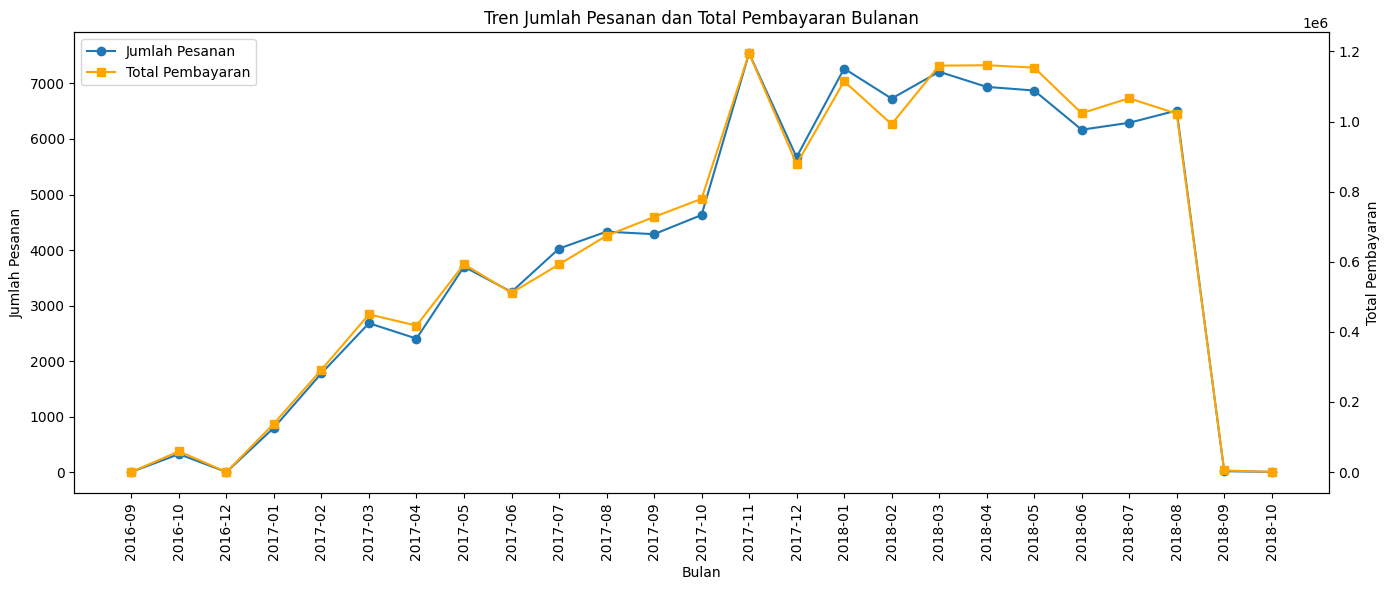

In [20]:

# Visualisasi jumlah pesanan dan total pembayaran bulanan
fig, ax1 = plt.subplots(figsize=(14, 6))

# Garis jumlah pesanan
line1 = ax1.plot(
    monthly_sales["month"],
    monthly_sales["total_orders"],
    marker="o",
    label="Jumlah Pesanan"
)
ax1.set_xlabel("Bulan")
ax1.set_ylabel("Jumlah Pesanan")
ax1.tick_params(axis="x", rotation=90)

# Garis total pembayaran pada sumbu kedua
ax2 = ax1.twinx()
line2 = ax2.plot(
    monthly_sales["month"],
    monthly_sales["total_payment"],
    marker="s",
    color="orange",
    label="Total Pembayaran"
)
ax2.set_ylabel("Total Pembayaran")

# Menggabungkan legenda kedua garis
lines = line1 + line2
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper left")

plt.title("Tren Jumlah Pesanan dan Total Pembayaran Bulanan")
fig.tight_layout()
plt.show()


In [22]:

# Menghitung perubahan jumlah pesanan dan total pembayaran
monthly_sales["order_change"] = monthly_sales["total_orders"].diff()
monthly_sales["payment_change"] = monthly_sales["total_payment"].diff()

# Menampilkan perubahan jumlah pesanan
print("Kenaikan jumlah pesanan terbesar:")
print(monthly_sales.loc[monthly_sales["order_change"].idxmax()])

print("\nPenurunan jumlah pesanan terbesar:")
print(monthly_sales.loc[monthly_sales["order_change"].idxmin()])

# Menampilkan perubahan total pembayaran
print("\nKenaikan total pembayaran terbesar:")
print(monthly_sales.loc[monthly_sales["payment_change"].idxmax()])

print("\nPenurunan total pembayaran terbesar:")
print(monthly_sales.loc[monthly_sales["payment_change"].idxmin()])


Kenaikan jumlah pesanan terbesar:
month               2017-11
total_orders           7544
total_payment     1194882.8
order_change         2913.0
payment_change    415204.92
Name: 13, dtype: object

Penurunan jumlah pesanan terbesar:
month                2018-09
total_orders              16
total_payment        4439.54
order_change         -6496.0
payment_change   -1017985.78
Name: 23, dtype: object

Kenaikan total pembayaran terbesar:
month               2017-11
total_orders           7544
total_payment     1194882.8
order_change         2913.0
payment_change    415204.92
Name: 13, dtype: object

Penurunan total pembayaran terbesar:
month                2018-09
total_orders              16
total_payment        4439.54
order_change         -6496.0
payment_change   -1017985.78
Name: 23, dtype: object


**Insight:**
- Berdasarkan hasil analisis, kenaikan jumlah pesanan terbesar terjadi pada November 2017, yaitu meningkat sebanyak 2.913 pesanan dibandingkan bulan sebelumnya. Pada bulan yang sama, total pembayaran juga mengalami kenaikan terbesar, yaitu sebesar 415.204,92. Hal ini menunjukkan adanya peningkatan aktivitas transaksi pelanggan pada periode tersebut.

- Sementara itu, penurunan jumlah pesanan terbesar terjadi pada September 2018, yaitu berkurang sebanyak 6.496 pesanan dibandingkan Agustus 2018. Total pembayaran juga mengalami penurunan terbesar pada bulan tersebut, yaitu sebesar 1.017.985,78.

### Pertanyaan 2: Bagaimana persentase pesanan yang terlambat dikirim dan rata-rata waktu pengiriman pada setiap bulan selama periode data yang tersedia?

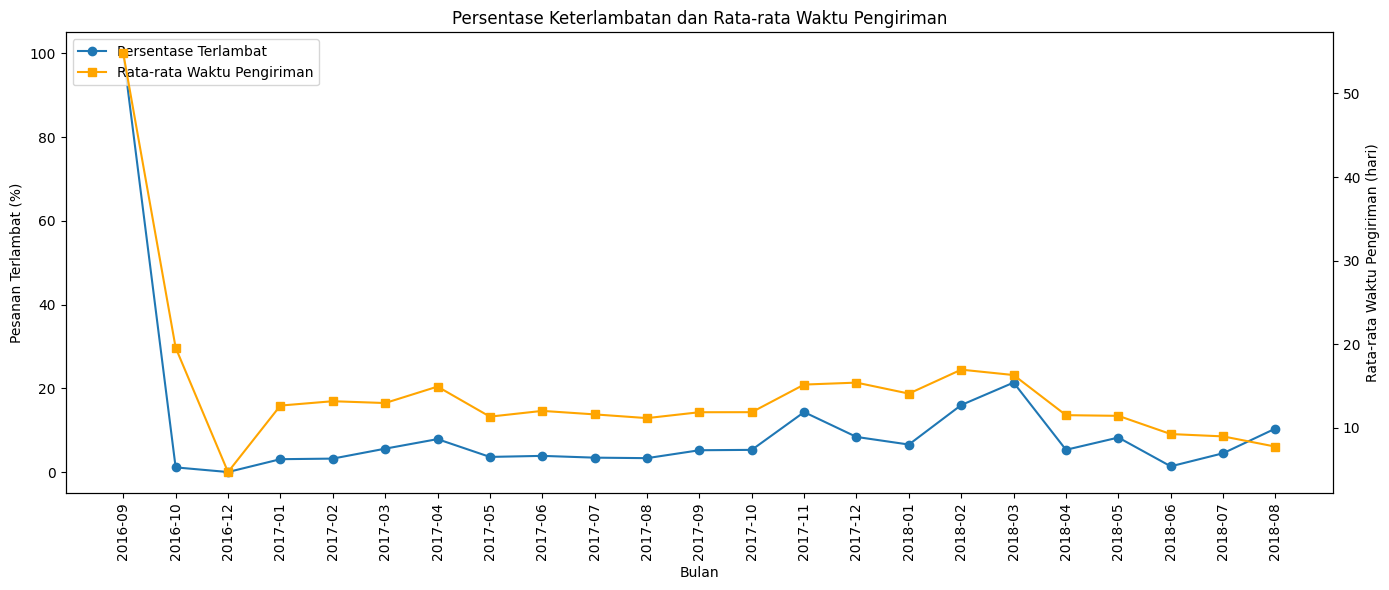

In [21]:

# Visualisasi hasil pengiriman bulanan
fig, ax1 = plt.subplots(figsize=(14, 6))

line1 = ax1.plot(
    monthly_delivery["month"],
    monthly_delivery["late_percentage"],
    marker="o",
    label="Persentase Terlambat"
)
ax1.set_xlabel("Bulan")
ax1.set_ylabel("Pesanan Terlambat (%)")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
line2 = ax2.plot(
    monthly_delivery["month"],
    monthly_delivery["avg_delivery_days"],
    marker="s",
    color="orange",
    label="Rata-rata Waktu Pengiriman"
)
ax2.set_ylabel("Rata-rata Waktu Pengiriman (hari)")

# Menggabungkan legenda kedua garis
lines = line1 + line2
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper left")

plt.title("Persentase Keterlambatan dan Rata-rata Waktu Pengiriman")
fig.tight_layout()
plt.show()


**Insight:** (Opsional)
- Rata-rata waktu pengiriman menunjukkan kecenderungan menurun pada pertengahan 2018. Pada Januari 2018, waktu pengiriman rata-rata sekitar 14,08 hari, kemudian menurun menjadi 11,50 hari pada April 2018 dan mencapai sekitar 7,73 hari pada Agustus 2018

## Analisis Lanjutan (Opsional)

### Pertanyaan 3: Bagaimana perbedaan rata-rata skor ulasan pelanggan antara pesanan yang dikirim tepat waktu dengan pesanan yang terlambat selama periode data yang tersedia?

In [18]:
# Menggabungkan data pesanan dengan ulasan pelanggan
orders_reviews_df = pd.merge(
    orders_df,
    order_reviews_df[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

# Menggunakan pesanan yang sudah memiliki tanggal pengiriman
orders_reviews_df = orders_reviews_df[
    orders_reviews_df["order_delivered_customer_date"].notna()
].copy()

# Menentukan status ketepatan waktu pengiriman
orders_reviews_df["delivery_status"] = np.where(
    orders_reviews_df["order_delivered_customer_date"]
    > orders_reviews_df["order_estimated_delivery_date"],
    "Terlambat",
    "Tepat Waktu"
)

# Menghitung rata-rata skor ulasan
review_comparison = orders_reviews_df.groupby(
    "delivery_status"
).agg(
    average_review_score=("review_score", "mean"),
    total_reviews=("review_score", "count")
).reset_index()

print(review_comparison)

  delivery_status  average_review_score  total_reviews
0     Tepat Waktu              4.293578          88658
1       Terlambat              2.566550           7701


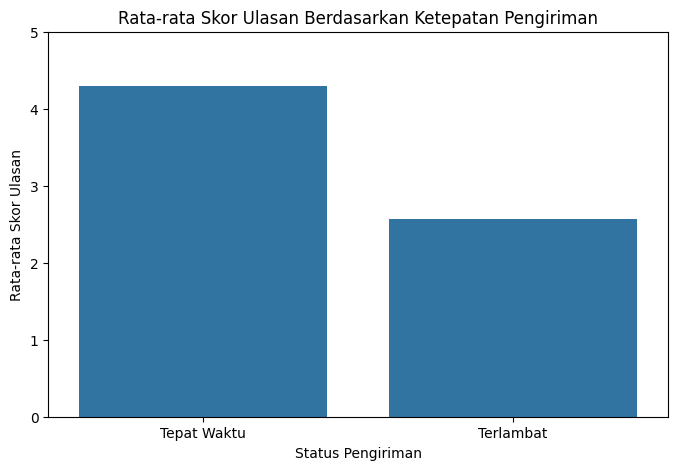

In [19]:
# Visualisasi perbandingan skor ulasan

plt.figure(figsize=(8, 5))

sns.barplot(
    data=review_comparison,
    x="delivery_status",
    y="average_review_score"
)

plt.title("Rata-rata Skor Ulasan Berdasarkan Ketepatan Pengiriman")
plt.xlabel("Status Pengiriman")
plt.ylabel("Rata-rata Skor Ulasan")
plt.ylim(0, 5)
plt.show()

**Insight:** (Opsional)
- Pesanan yang dikirim tepat waktu memiliki rata-rata skor ulasan sekitar 4,3 dari 5, sedangkan pesanan yang terlambat memiliki rata-rata skor sekitar 2,6 dari 5

- Kemudian terdapat selisih rata-rata skor ulasan sekitar 1,7 poin antara kedua kelompok. Nah hal ini menunjukkan bahwa keterlambatan pengiriman berkaitan dengan skor ulasan pelanggan yang lebih rendah

- Hasil ini membuktikan bahwa ketepatan waktu pengiriman merupakan salah satu aspek yang perlu diperhatikan untuk meningkatkan pengalaman dan kepuasan pelanggan

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan hasil analisis, jumlah pesanan dan total pembayaran secara umum mengalami peningkatan dari tahun 2017 hingga sebagian besar tahun 2018, meskipun terdapat beberapa bulan yang mengalami penurunan. Jumlah pesanan tertinggi terjadi pada November 2017 sebanyak 7.544 pesanan, sedangkan total pembayaran tertinggi terjadi pada April 2018 sebesar 1.160.785,48
- **Conclusion pertanyaan 2:** Persentase keterlambatan tertinggi dalam data yang tersedia terjadi pada Maret 2018 sebesar 21,36%, sedangkan rata-rata waktu pengiriman terlama tercatat pada September 2016 sekitar 54,81 hari. Pada Agustus 2018, rata-rata waktu pengiriman turun menjadi sekitar 7,73 hari. Hal ini menunjukkan bahwa kinerja pengiriman perlu dievaluasi secara berkala dengan memperhatikan ketepatan waktu dan durasi pengiriman
- **Conclusion pertanyaan 3:** Hasil analisis menunjukkan bahwa pesanan yang dikirim tepat waktu memiliki rata-rata skor ulasan sekitar 4,3 dari 5, sedangkan pesanan yang terlambat memperoleh skor sekitar 2,6 dari 5. Perbedaan ini menunjukkan adanya hubungan antara ketepatan waktu pengiriman dan penilaian pelanggan. Oleh karena itu, ketepatan pengiriman menjadi salah satu aspek penting yang perlu diperhatikan untuk meningkatkan pengalaman pelanggan.

**Rekomendasi Action Item:**
- Melakukan evaluasi terhadap proses pengiriman, terutama pada bulan dengan persentase keterlambatan tinggi, seperti Maret 2018

- Memantau jumlah pesanan, total pembayaran, persentase keterlambatan, dan rata-rata waktu pengiriman setiap bulan untuk membantu mengidentifikasi perubahan kinerja

- Mengevaluasi estimasi waktu pengiriman agar sesuai dengan kondisi operasional

- Menggunakan skor ulasan pelanggan sebagai salah satu indikator untuk mengevaluasi kualitas layanan dan menentukan perbaikan yang diperlukan